In [1]:
import torch, torchvision
from datasets import load_dataset
from torchvision import transforms

C:\Users\litwi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# CIFAR-10 image classifier in PyTorch

**Goal:** understand 100% of how a CNN is trained. We write the code as small **functions**, so each one can be reused, tested and explained.

**Data:** 60k color images, 32x32, 10 classes. Split: **45k train / 5k val / 10k test**. Decisions are made on validation; the test set is run **once, at the end**.

---

## Step 1: data
Write these functions, in this order:
1. `load_cifar()` → loads CIFAR-10 from Hugging Face, returns `ds`
2. `apply_transform(batch)` → turns every PIL image in the batch into a tensor (`ToTensor`), returns the batch
3. `split_train_val(train_data, val_size=5000, seed=42)` → returns `train_set, val_set` (`random_split` with a seeded generator)
4. `make_loader(dataset, batch_size=64, shuffle=False)` → returns a `DataLoader`
5. `check_batch(loader)` → prints the shape of images and labels of one batch

**I understand it when I can explain:** the batch shape `(N, C, H, W)`, what a label is, why we need validation, why only train is shuffled.

## Step 2: MLP baseline and training loop
1. `get_device()` → returns `"cuda"`, `"mps"` or `"cpu"`
2. `build_mlp()` → returns a simple MLP (flatten, 2 hidden layers)
3. `count_parameters(model)` → returns the number of trainable parameters
4. `train_one_epoch(model, loader, loss_fn, optimizer, device)` → forward, loss, `zero_grad`, `backward`, `step`; returns mean train loss
5. `evaluate(model, loader, loss_fn, device)` → uses `model.eval()` and `torch.no_grad()`; returns val loss and accuracy
6. `fit(model, train_loader, val_loader, epochs, lr, device)` → loops over epochs, returns a `history` dict
7. `plot_history(history)` → plots train loss, val loss and val accuracy

**I understand it when I can explain:** each line of `train_one_epoch`, `backward()` vs `step()`, what `model.eval()` is for.

## Step 3: own CNN
1. `build_cnn()` → 3 blocks of Conv → BatchNorm → ReLU → MaxPool + Linear head
2. Before running: work out the shape after every layer on paper, then verify with `print(x.shape)`
3. Reuse `count_parameters`, `fit`, `plot_history` and compare with the MLP

**I understand it when I can explain:** where each shape comes from, why a CNN has fewer parameters than an MLP, what pooling does.

## Step 4: experiments (one change at a time)
1. `build_train_transform(augment)` → returns the transform with or without augmentation (`RandomCrop`, `RandomHorizontalFlip`)
2. `build_cnn(dropout)` → CNN with an optional dropout parameter
3. `run_experiment(name, **settings)` → builds, trains, returns val accuracy and parameters
4. Compare: augmentation yes/no, dropout yes/no, two learning rates; fill the table below

**I understand it when I can explain:** how to spot overfitting on a plot and how each regularization technique works.

## Step 5: transfer learning
1. `build_resnet18(num_classes=10, freeze=True)` → ImageNet weights, new last layer, optionally frozen body
2. Stage 1: train only the new layer (`fit`)
3. `unfreeze(model)` → makes all parameters trainable; Stage 2 with a small learning rate
4. `test_final(model, test_loader, device)` → run the test set **once**, for the single best model

**I understand it when I can explain:** why we freeze first, and why the unfrozen model uses a smaller learning rate.

---

## Results table

| Model / variant | Parameters | Val accuracy |
|---|---|---|
| MLP (baseline) | | |
| Own CNN | | |
| CNN + augmentation | | |
| CNN + dropout | | |
| ResNet18 (transfer learning) | | |

*Rough expectations (hypotheses): MLP 50-55%, CNN 75-80%, CNN + augmentation 80-85%, ResNet18 85%+.*

## Pass criteria
Working notebook, train/val plot, a table with at least four variants, I can answer the questions above without notes, and the test set was used exactly once.

## Step 1: data
## Write these functions, in this order:
1. `load_cifar()` → loads CIFAR-10 from Hugging Face, returns `ds`
2. `apply_transform(batch)` → turns every PIL image in the batch into a tensor (`ToTensor`), returns the batch
3. `split_train_val(train_data, val_size=5000, seed=42)` → returns `train_set, val_set` (`random_split` with a seeded generator)
4. `make_loader(dataset, batch_size=64, shuffle=False)` → returns a `DataLoader`
5. `check_batch(loader)` → prints the shape of images and labels of one batch

**I understand it when I can explain:** the batch shape `(N, C, H, W)`, what a label is, why we need validation, why only train is shuffled.

## 1. `load_cifar()` → loads CIFAR-10 from Hugging Face, returns `ds`

In [10]:
def load_cifar():
    """Download CIFAR-10 from Hugging Face and return it as a DatasetDict."""
    ds = load_dataset("uoft-cs/cifar10")
    return ds

In [11]:
# Converter created once and reused for every image:
# PIL image -> tensor, layout (C, H, W), values scaled to 0-1
to_tensor = transforms.ToTensor()

example

In [12]:
ds = load_cifar()

In [13]:
sample = ds["train"][0]
print(type(sample["img"]), sample["img"].size, sample["label"])

<class 'PIL.PngImagePlugin.PngImageFile'> (32, 32) 0


In [14]:
x = to_tensor(sample["img"])
print(type(x), x.shape, x.dtype)
print(x.min(), x.max())

<class 'torch.Tensor'> torch.Size([3, 32, 32]) torch.float32
tensor(0.1333) tensor(0.7961)


## 2. `apply_transform(batch)` → turns every PIL image in the batch into a tensor (`ToTensor`), returns the batch


In [15]:
def apply_transform(batch):
    """Convert every PIL image in the batch to a tensor."""
    tensors = []
    for img in batch['img']:
        tensors.append(to_tensor(img))
    batch['img'] = tensors
    return batch

In [20]:
# with_transform registers apply_transform as a lazy "filter" on the dataset:
# - the stored data in ds stays unchanged (images are still PIL)
# - the function runs on the fly, only when rows are read (e.g. by a DataLoader)
# - it receives a dict of lists (a batch) and must return the same dict
# - good for random augmentation: it re-runs on every read, so the same image can look different in each epoch
train_data = ds["train"].with_transform(apply_transform)
train_data[0]["img"].shape

torch.Size([3, 32, 32])

In [59]:
test_data = ds["test"].with_transform(apply_transform)
test_data[0]["img"].shape

torch.Size([3, 32, 32])

example photo

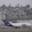

In [21]:
ds["train"][0]["img"]

## 3. `split_train_val(train_data, val_size=5000, seed=42)` → returns `train_set, val_set` (`random_split` with a seeded generator)

In [22]:
from torch.utils.data import random_split

In [23]:
def split_train_val(train_data, val_size=5000, seed=42):
    """Split train_data into train and validation sets (reproducible)."""
    train_size = len(train_data) - val_size
    generator = torch.Generator().manual_seed(seed)
    train_set, val_set = random_split(train_data, [train_size, val_size], generator=generator)
    return train_set, val_set

spliting into train and val set

In [27]:
train_set, val_set = split_train_val(train_data)
print(f"Length of training set {len(train_set)} and val set {len(val_set)}")

Length of training set 45000 and val set 5000


## 4. `make_loader(dataset, batch_size=64, shuffle=False)` → returns a `DataLoader`

In [28]:
from torch.utils.data import DataLoader

In [30]:
def make_loader(dataset, batch_size=64, shuffle=False):
    """Wrap a dataset in a DataLoader that yields batches."""
    # DataLoader groups single examples into batches of `batch_size`.
    # Each batch is collated into tensors, e.g. images (N, 3, 32, 32).
    # shuffle=True reshuffles the order at the start of every epoch
    # (use it for train only; val/test don't need it).
    # We return the loader so the caller can iterate over the batches.
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

In [34]:
# Training loader: serves train_set (45k examples) in batches of 64 - > 45k /64 = 704
# shuffle=True reorders the examples every epoch, so the model doesn't
# see them in the same order each time. Nothing is loaded yet; batches
# are produced (and transformed) only when we iterate over the loader.
train_loader = make_loader(train_set, shuffle=True)

In [39]:
len(train_loader)

704

Pipline

ds                 -> raw dataset from Hugging Face (PIL images)

train_data         -> ds["train"] + apply_transform (tensors on read)

train_set, val_set -> 45k / 5k split of train_data

train_loader       -> train_set served in shuffled batches of 64

In [40]:
# Validation loader: no shuffling needed, we only measure performance.
val_loader = make_loader(val_set)
len(val_loader)

79

dict from hugging face - img : label

In [61]:
test_loader = make_loader(test_data)
len(test_loader)

157

 Number of batches per loader = ceil(number of examples / batch_size).

In [62]:
print(len(train_loader), len(val_loader), len(test_loader))

704 79 157


Number of individual examples (images + labels) in each set

In [64]:
print(len(train_set), len(val_set), len(test_data))

45000 5000 10000


In [42]:
batch = next(iter(train_loader))
print(type(batch))
print(batch.keys())

<class 'dict'>
dict_keys(['img', 'label'])


## 5. `check_batch(loader)` → prints the shape of images and labels of one batch

In [55]:
def check_batch(loader):
    """Print the types, shapes and dtypes of images and labels in one batch."""
    batch = next(iter(loader))   # take one batch (a dict) from the loader
    x = batch["img"]             # images: (batch, channels, height, width)
    y = batch["label"]           # labels: (batch,), one class index per image
    print(f"x: type={type(x)}, shape={x.shape}, dtype={x.dtype}")
    print(f"y: type={type(y)}, shape={y.shape}, dtype={y.dtype}")

In [56]:
check_batch(train_loader)

x: type=<class 'torch.Tensor'>, shape=torch.Size([64, 3, 32, 32]), dtype=torch.float32
y: type=<class 'torch.Tensor'>, shape=torch.Size([64]), dtype=torch.int64


 x - a batch of 64 images, each with 3 channels (RGB) and 32 x 32 pixels
     shape (64, 3, 32, 32), dtype float32, pixel values scaled to 0-1
     
 y - 64 labels, one label per image (class index 0-9)
     shape (64,), dtype int64

## Step 2: MLP baseline and training loop
1. `get_device()` → returns `"cuda"`, `"mps"` or `"cpu"`
2. `build_mlp()` → returns a simple MLP (flatten, 2 hidden layers)
3. `count_parameters(model)` → returns the number of trainable parameters
4. `train_one_epoch(model, loader, loss_fn, optimizer, device)` → forward, loss, `zero_grad`, `backward`, `step`; returns mean train loss
5. `evaluate(model, loader, loss_fn, device)` → uses `model.eval()` and `torch.no_grad()`; returns val loss and accuracy
6. `fit(model, train_loader, val_loader, epochs, lr, device)` → loops over epochs, returns a `history` dict
7. `plot_history(history)` → plots train loss, val loss and val accuracy

**I understand it when I can explain:** each line of `train_one_epoch`, `backward()` vs `step()`, what `model.eval()` is for.

In [66]:
def get_device():
    """Return the best available device: cuda, mps or cpu."""
    if torch.cuda.is_available():            # NVIDIA GPU
        return "cuda"
    if torch.backends.mps.is_available():    # Apple Silicon GPU (Mac)
        return "mps"
    return "cpu"                             # fallback: plain processor

In [67]:
device = get_device()
device

'cpu'

# 2. `build_mlp()` → returns a simple MLP (flatten, 2 hidden layers)


In [68]:
import torch.nn as nn

In [75]:
def build_mlp():
    """Simple MLP: flatten -> 2 hidden layers -> class scores."""
    return nn.Sequential(
        nn.Flatten(),             # (N, 3, 32, 32) -> (N, 3072); keeps the batch dim
        nn.Linear(3072, 512),      # input size = number of values in one flat image
        nn.ReLU(),                # non-linearity between layers
        nn.Linear(512, 256),      # second hidden layer
        nn.ReLU(),
        nn.Linear(256, 10),      # output size = number of classes
    )
model = build_mlp()
out = model(x)
print(out.shape)

torch.Size([64, 10])


In [76]:
# Model output: logits
# out has shape (64, 10): for each of the 64 images, 10 raw scores,
# one per CIFAR-10 class (0 = airplane, ..., 9 = truck).
# Higher score = the model "believes" more in that class.
# These are logits, NOT probabilities: they can be negative and
# don't sum to 1. The model is untrained, so scores are close
# to each other and predictions are close to random (~10% accuracy).

print(out[0])                 # 10 scores for the first image
print(out.argmax(dim=1)[:10]) # predicted class of the first 10 images
print(y[:10])                 # true labels, for comparison

tensor([ 0.1036,  0.0185,  0.0608, -0.0090, -0.0416, -0.0366, -0.0172,  0.0721,
         0.0755, -0.0617], grad_fn=<SelectBackward0>)
tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])
tensor([0, 1, 2, 2, 9, 1, 6, 6, 4, 9])


In [77]:
# softmax turns the 10 logits into probabilities (0-1, sum = 1)
probs = torch.softmax(out[0], dim=0)
print(probs, probs.sum())

tensor([0.1089, 0.1001, 0.1044, 0.0973, 0.0942, 0.0947, 0.0965, 0.1056, 0.1059,
        0.0923], grad_fn=<SoftmaxBackward0>) tensor(1., grad_fn=<SumBackward0>)


### Untrained model = undecided
Softmax gives ~10% to every class (1 / 10): a uniform guess, because the weights are still random.
Expected initial loss: **-ln(0.1) ≈ 2.30**.

## 3. `count_parameters(model)` → returns the number of trainable parameters


In [78]:
def count_parameters(model):
    """Return the number of trainable parameters in the model."""
    total = 0                      # running sum of parameters
    for p in model.parameters():   # every weight and bias tensor, one by one
        total += p.numel()               # number of elements in tensor p
        print(p.shape, p.numel())
    return total
count_parameters(model)

torch.Size([512, 3072]) 1572864
torch.Size([512]) 512
torch.Size([256, 512]) 131072
torch.Size([256]) 256
torch.Size([10, 256]) 2560
torch.Size([10]) 10


1707274

## 4. `train_one_epoch(model, loader, loss_fn, optimizer, device)` → forward, loss, `zero_grad`, `backward`, `step`; returns mean train loss

In [80]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):
    """Train the model for one epoch and return the mean train loss."""
    model.train()                          # training mode
    total_loss = 0.0                       # sum of per-example losses

    for batch in loader:                   # NEW: loop over all batches
        xb = batch["img"].to(device)       # NEW: images -> same device as model
        yb = batch["label"].to(device)     # NEW: labels -> same device as model

        optimizer.zero_grad()              # 1. clear old gradients
        output = model(xb)                 # 2. forward pass
        loss = loss_fn(output, yb)         # 3. compute loss
        loss.backward()                    # 4. backprop: gradients
        optimizer.step()                   # 5. update weights

        total_loss += loss.item() * xb.size(0)   # NEW: accumulate loss

    return total_loss / len(loader.dataset)      # NEW: mean loss per example

result after one epoch

In [82]:
device = get_device()
model = build_mlp().to(device)                 # model must be moved to device too
loss_fn = nn.CrossEntropyLoss()                # clasification - we have 0 classes 
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer, device)
print(train_loss)

1.8577371028052436


## 5. `evaluate(model, loader, loss_fn, device)` → uses `model.eval()` and `torch.no_grad()`; returns val loss and accuracy

In [85]:
def evaluate(model, loader, loss_fn, device):
    """Return (mean loss, accuracy) of the model on the given loader."""
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for batch in loader:
            xb = batch["img"].to(device)                   # images -> device
            yb = batch["label"].to(device)                   # labels -> device
            output = model(xb)               # forward pass
            loss = loss_fn(output, yb)
            total_loss += loss.item() * xb.size(0)          # same as in train_one_epoch
            correct += (output.argmax(dim=1) == yb).sum().item()             # how many predictions are right in this batch?
    n = len(loader.dataset)
    return total_loss / n, correct / n

acc and val loss after one epoch

In [86]:
val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)
print(val_loss, val_acc)

1.8013776435852051 0.3438


## 6. `fit(model, train_loader, val_loader, epochs, lr, device)` → loops over epochs, returns a `history` dict


In [89]:
def fit(model, train_loader, val_loader, epochs, lr, device):
    """Train for several epochs and return a history of the metrics."""
    model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer, device)                # one epoch of training
        val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)        # measure on validation
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"epoch {epoch + 1}/{epochs} | train {train_loss:.3f} "
              f"| val {val_loss:.3f} | acc {val_acc:.3f}")
    return history

epochs = x * 45 k training photos

In [91]:
model = build_mlp()
history = fit(model, train_loader, val_loader, epochs=10, lr=1e-3, device=device)

epoch 1/10 | train 1.851 | val 1.699 | acc 0.381
epoch 2/10 | train 1.663 | val 1.612 | acc 0.427
epoch 3/10 | train 1.577 | val 1.675 | acc 0.389
epoch 4/10 | train 1.524 | val 1.583 | acc 0.437
epoch 5/10 | train 1.482 | val 1.551 | acc 0.444
epoch 6/10 | train 1.450 | val 1.497 | acc 0.464
epoch 7/10 | train 1.419 | val 1.503 | acc 0.462
epoch 8/10 | train 1.393 | val 1.445 | acc 0.485
epoch 9/10 | train 1.374 | val 1.432 | acc 0.487
epoch 10/10 | train 1.350 | val 1.435 | acc 0.485


## 7. `plot_history(history)` → plots train loss, val loss and val accuracy

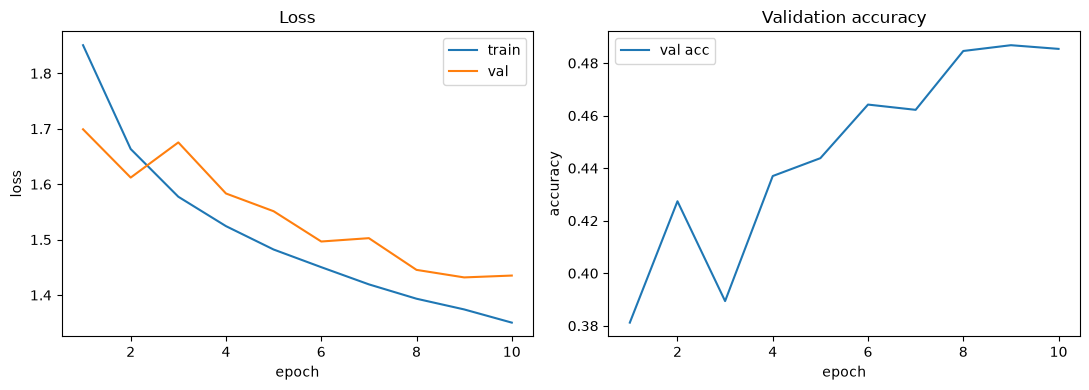

In [92]:
import matplotlib.pyplot as plt


def plot_history(history):
    """Plot train/val loss and val accuracy per epoch."""
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))

    # Left panel: loss curves
    ax_loss.plot(epochs, history["train_loss"], label="train")
    ax_loss.plot(epochs, history["val_loss"], label="val")      # blank 1
    ax_loss.set_xlabel("epoch")
    ax_loss.set_ylabel("loss")
    ax_loss.set_title("Loss")
    ax_loss.legend()

    # Right panel: validation accuracy
    ax_acc.plot(epochs, history["val_acc"], label="val acc")   # blank 2
    ax_acc.set_xlabel("epoch")
    ax_acc.set_ylabel("accuracy")
    ax_acc.set_title("Validation accuracy")
    ax_acc.legend()

    plt.tight_layout()
    plt.show()


plot_history(history)